In [2]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import confusion_matrix


# ============================================================
# Device
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Device:", device)

Device: cuda


In [3]:
# ============================================================
# Hyperparameters
# ============================================================

BATCH_SIZE = 128
LEARNING_RATE = 1e-3
EPOCHS = 15


# ============================================================
# Dataset
# ============================================================

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)



In [5]:
# ============================================================
# CNN
# ============================================================

class CNN(nn.Module):

    def __init__(self):

        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(
                1,
                16,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),

            nn.MaxPool2d(2),

            nn.Conv2d(
                16,
                32,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),

            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(

            nn.Linear(
                32 * 7 * 7,
                128
            ),

            nn.ReLU(),

            nn.Linear(
                128,
                10
            )
        )

    def forward(self, x):

        x = self.features(x)

        x = torch.flatten(
            x,
            start_dim=1
        )

        x = self.classifier(x)

        return x


model = CNN().to(device)

In [6]:
# ============================================================
# Loss and Optimizer
# ============================================================

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)


# ============================================================
# Train / Evaluate Functions
# ============================================================

def train_one_epoch():

    model.train()

    running_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        running_loss += (
            loss.item()
            * images.size(0)
        )

    return running_loss / len(train_loader.dataset)


@torch.no_grad()
def evaluate(loader):

    model.eval()

    running_loss = 0.0

    correct = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        running_loss += (
            loss.item()
            * images.size(0)
        )

        predictions = outputs.argmax(1)

        correct += (
            predictions == labels
        ).sum().item()

    loss = running_loss / len(loader.dataset)

    accuracy = (
        correct
        / len(loader.dataset)
    )

    return loss, accuracy



In [7]:
# ============================================================
# Training
# ============================================================

train_losses = []
test_losses = []

train_accs = []
test_accs = []

for epoch in range(EPOCHS):

    train_loss = train_one_epoch()

    train_eval_loss, train_acc = evaluate(
        train_loader
    )

    test_loss, test_acc = evaluate(
        test_loader
    )

    train_losses.append(train_eval_loss)
    test_losses.append(test_loss)

    train_accs.append(train_acc)
    test_accs.append(test_acc)

    print(
        f"Epoch {epoch+1:02d} | "
        f"Train Loss={train_eval_loss:.4f} | "
        f"Test Loss={test_loss:.4f} | "
        f"Train Acc={train_acc:.4f} | "
        f"Test Acc={test_acc:.4f}"
    )


Epoch 01 | Train Loss=0.0843 | Test Loss=0.0775 | Train Acc=0.9753 | Test Acc=0.9758
Epoch 02 | Train Loss=0.0560 | Test Loss=0.0539 | Train Acc=0.9822 | Test Acc=0.9818
Epoch 03 | Train Loss=0.0418 | Test Loss=0.0440 | Train Acc=0.9870 | Test Acc=0.9849
Epoch 04 | Train Loss=0.0387 | Test Loss=0.0428 | Train Acc=0.9879 | Test Acc=0.9861
Epoch 05 | Train Loss=0.0207 | Test Loss=0.0296 | Train Acc=0.9939 | Test Acc=0.9897
Epoch 06 | Train Loss=0.0183 | Test Loss=0.0299 | Train Acc=0.9945 | Test Acc=0.9896
Epoch 07 | Train Loss=0.0162 | Test Loss=0.0291 | Train Acc=0.9953 | Test Acc=0.9905
Epoch 08 | Train Loss=0.0131 | Test Loss=0.0314 | Train Acc=0.9964 | Test Acc=0.9899
Epoch 09 | Train Loss=0.0119 | Test Loss=0.0341 | Train Acc=0.9960 | Test Acc=0.9897
Epoch 10 | Train Loss=0.0104 | Test Loss=0.0326 | Train Acc=0.9967 | Test Acc=0.9903
Epoch 11 | Train Loss=0.0069 | Test Loss=0.0285 | Train Acc=0.9981 | Test Acc=0.9913
Epoch 12 | Train Loss=0.0081 | Test Loss=0.0340 | Train Acc=0.997

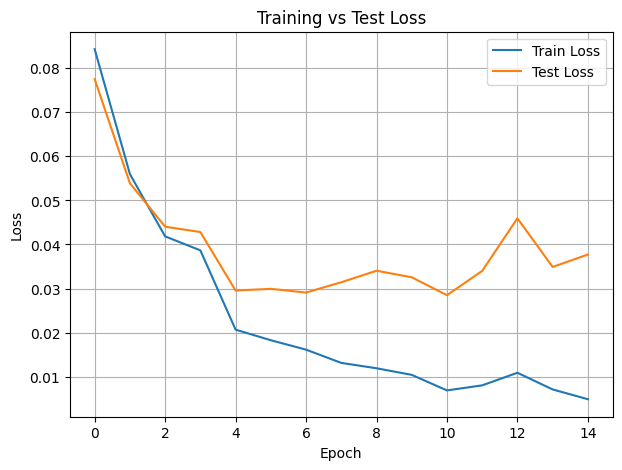

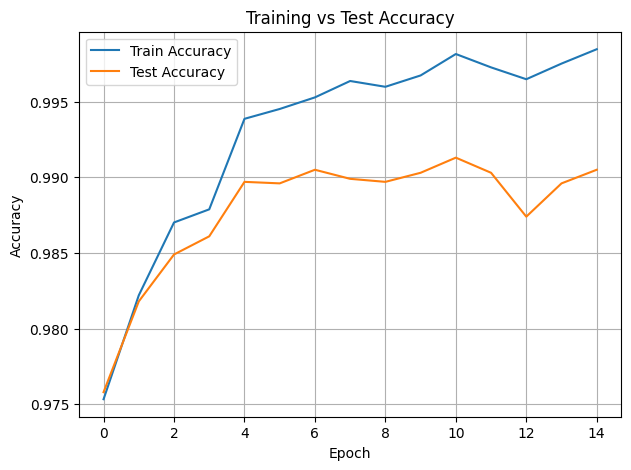

In [8]:
# ============================================================
# Loss Plot
# ============================================================

plt.figure(figsize=(7,5))

plt.plot(
    train_losses,
    label="Train Loss"
)

plt.plot(
    test_losses,
    label="Test Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Training vs Test Loss"
)

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# Accuracy Plot
# ============================================================

plt.figure(figsize=(7,5))

plt.plot(
    train_accs,
    label="Train Accuracy"
)

plt.plot(
    test_accs,
    label="Test Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "Training vs Test Accuracy"
)

plt.legend()
plt.grid(True)

plt.show()



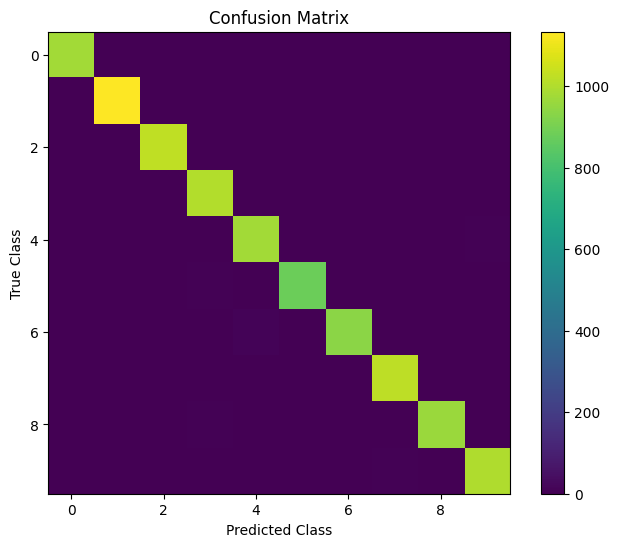

In [9]:

# ============================================================
# Predictions
# ============================================================

model.eval()

all_labels = []
all_preds = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        preds = outputs.argmax(1)

        all_labels.extend(
            labels.numpy()
        )

        all_preds.extend(
            preds.cpu().numpy()
        )


# ============================================================
# Confusion Matrix
# ============================================================

cm = confusion_matrix(
    all_labels,
    all_preds
)

plt.figure(figsize=(8,6))

plt.imshow(cm)

plt.colorbar()

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "True Class"
)

plt.title(
    "Confusion Matrix"
)

plt.show()



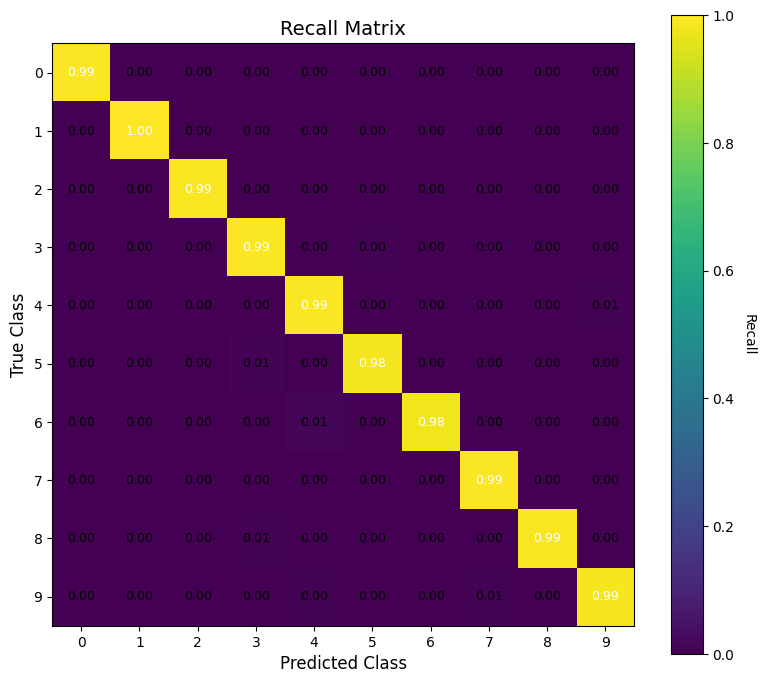

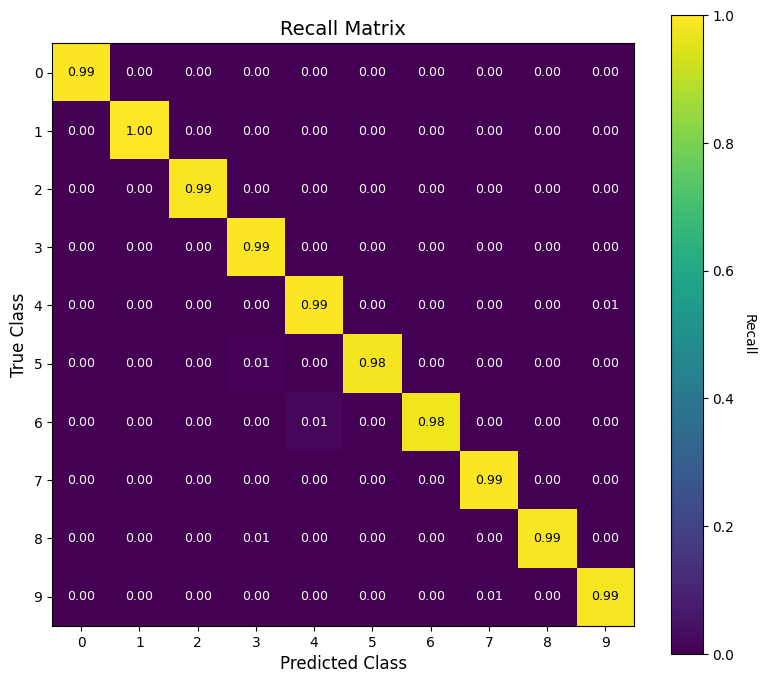

In [ ]:
# ============================================================
# Recall Matrix Heatmap (Publication Style)
# ============================================================

recall_matrix = cm.astype(float)

recall_matrix /= (
    recall_matrix.sum(
        axis=1,
        keepdims=True
    )
)

fig, ax = plt.subplots(
    figsize=(8, 7)
)

im = ax.imshow(
    recall_matrix,
    cmap="viridis",
    vmin=0,
    vmax=1
)

# --------------------------------------------------
# Colorbar
# --------------------------------------------------

cbar = plt.colorbar(
    im,
    ax=ax
)

cbar.set_label(
    "Recall",
    rotation=270,
    labelpad=15
)

# --------------------------------------------------
# Axis labels
# --------------------------------------------------

classes = np.arange(10)

ax.set_xticks(classes)
ax.set_yticks(classes)

ax.set_xlabel(
    "Predicted Class",
    fontsize=12
)

ax.set_ylabel(
    "True Class",
    fontsize=12
)

ax.set_title(
    "Recall Matrix",
    fontsize=14
)

# --------------------------------------------------
# Write recall values inside cells
# --------------------------------------------------

for i in range(recall_matrix.shape[0]):

    for j in range(recall_matrix.shape[1]):

        value = recall_matrix[i, j]

        ax.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center",
            color="white" if value < 0.5 else "black",
            fontsize=9
        )

# --------------------------------------------------
# Publication-style formatting
# --------------------------------------------------

ax.set_aspect("equal")

fig.tight_layout()

plt.show()